In [2]:
doc1 = """Avstrijska prestolnica prebivalcem nudi številne oblike socialne podpore. Kljub temu marsikdo ni seznanjen s svojimi možnostmi oziroma ne ve, na koga se lahko obrne za pomoč. V takšnih primerih si na Dunaju medsebojno na pomoč priskočijo kar prebivalci, ki so včlanjeni v prostovoljno društvo "Stadtmenschen" (Meščani). V društvu ljudem pomagajo pri reševanju administrativnih opravil in spodbujajo družbeno solidarnost.

Mesto Dunaj v sodelovanju z različnimi ustanovami in društvi prebivalcem nudi številne socialne storitve in podporo. Številni prebivalci Dunaja, sicer opravičeni do pomoči, sami velikokrat ne najdejo pravih informacij. Poleg tega marsikdo nima razvite socialne mreže, na katero bi se lahko obrnili za pomoč. Ker se na Dunaju težave zavedajo in prebivalcem želijo poenostaviti dostop do ustrezne pomoči, so ustanovili prostovoljno društvo "Stadtmenschen" (v prevodu "Mestni ljudje"), ki poleg administrativne pomoči spodbuja tudi družbeno solidarnost.

V društvu prebivalce Dunaja seznanjajo s socialnimi storitvami, ki jih mesto nudi, in jim pomagajo pri spopadanju z vsakdanjimi administrativnimi opravki. Kdor želi zaprositi za stanovanjsko subvencijo ali podporo za minimalni dohodek, mu prostovoljci pomagajo najti in ustrezno izpolniti obrazec. Prostovoljci someščane po potrebi spremljajo tudi na sestankih. Društvo namreč nudi različne načine podpore: osnovne govorilne ure, ki so namenjene predstavitvi možnosti, ki jih mesto Dunaj nudi, spremstvo in podporo pri upravnih postopkih ter poglobljeno sodelovanje pri vsakdanjih opravkih.

V društvo je trenutno včlanjenih 80 prostovoljcev, ves čas pa iščejo nove okrepitve. Samo z govorilnimi urami vsako leto pomagajo približno 600 prebivalcem. Ob včlanitvi je obvezen tečaj, na katerem se prostovoljci podrobno seznanijo z vsemi socialnimi storitvami mesta, da lahko po najboljših močeh pomagajo svojim someščanom.
Spletna stran društva (v nemščini)"""

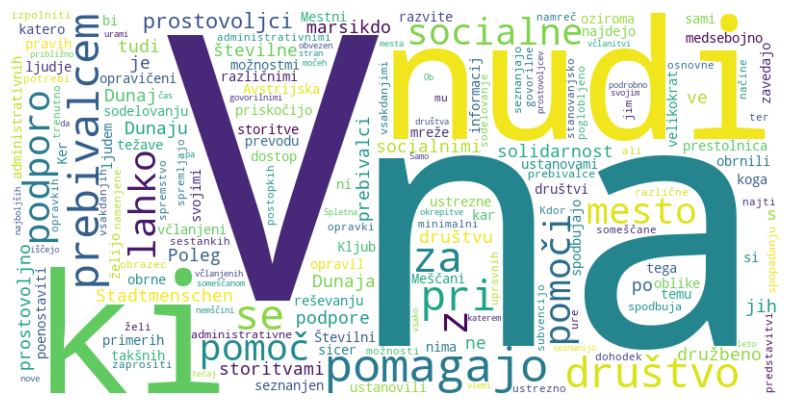

In [13]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

def generate_wordcloud(text):
    # Generate a word cloud object
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)

    # Display the generated word cloud using matplotlib
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  # Turn off axis labels
    plt.show()

generate_wordcloud(doc1)


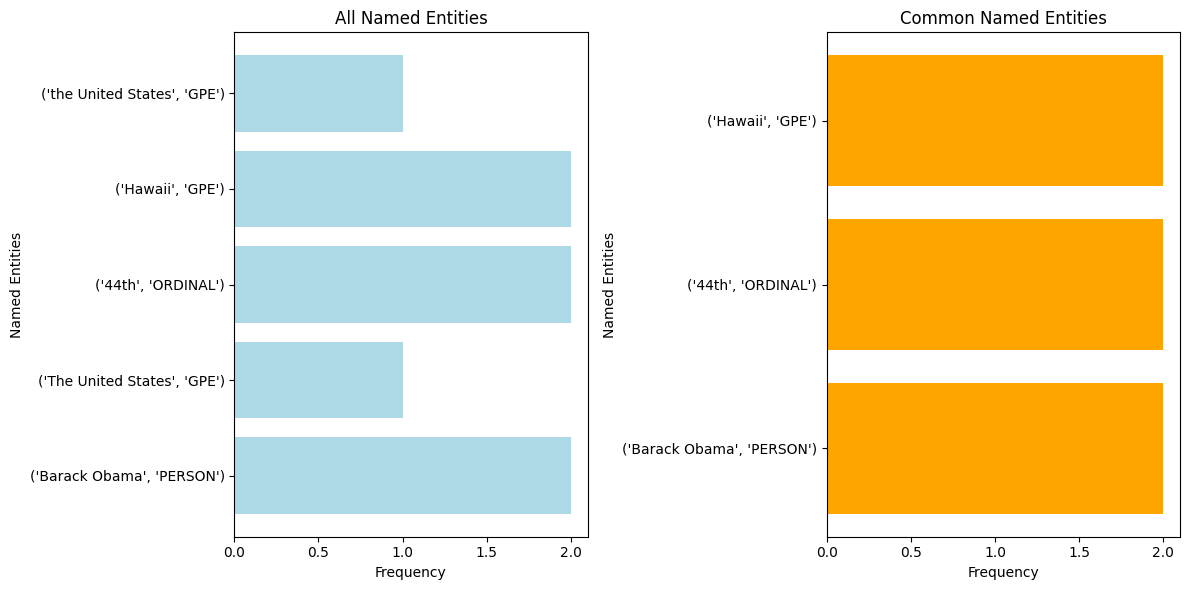

In [5]:
import spacy
import matplotlib.pyplot as plt
from collections import Counter

# Load spaCy model for named entity recognition
nlp = spacy.load("en_core_web_sm")

def get_named_entities(text):
    # Process the text using spaCy NLP pipeline
    doc = nlp(text)
    
    # Extract named entities and their labels
    entities = [(ent.text, ent.label_) for ent in doc.ents]
    
    return entities

def visualize_all_and_common_named_entities(text1, text2):
    # Get named entities from both texts
    entities1 = get_named_entities(text1)
    entities2 = get_named_entities(text2)

    # Extract unique named entities
    all_entities = set(entities1 + entities2)
    
    # Extract common named entities
    common_entities = set(entities1) & set(entities2)

    # Count the occurrences of each entity for setting the width
    entity_counts = Counter(entities1 + entities2)

    # Visualize all named entities
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.barh([str(entity) for entity in all_entities], [entity_counts[entity] for entity in all_entities], color='lightblue')
    plt.xlabel('Frequency')
    plt.ylabel('Named Entities')
    plt.title('All Named Entities')

    # Visualize common named entities
    plt.subplot(1, 2, 2)
    plt.barh([str(entity) for entity in common_entities], [entity_counts[entity] for entity in common_entities], color='orange')
    plt.xlabel('Frequency')
    plt.ylabel('Named Entities')
    plt.title('Common Named Entities')

    plt.tight_layout()
    plt.show()

# Example texts
text1 = "Barack Obama was born in Hawaii. He served as the 44th President of the United States."
text2 = "Hawaii is a beautiful island. The United States had its 44th President, Barack Obama."

# Visualize all and common named entities
visualize_all_and_common_named_entities(text1, text2)


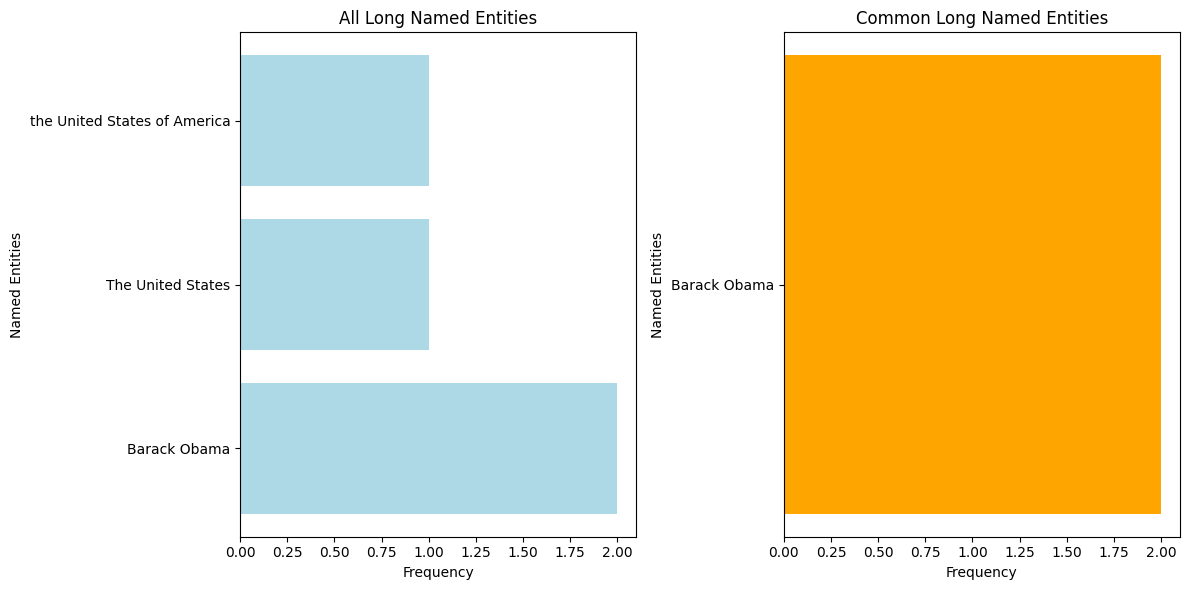

In [6]:
import spacy
import matplotlib.pyplot as plt
from collections import Counter

# Load spaCy model for named entity recognition
nlp = spacy.load("en_core_web_sm")

def get_long_named_entities(text, min_words=2):
    # Process the text using spaCy NLP pipeline
    doc = nlp(text)
    
    # Extract named entities and their labels
    entities = [ent.text for ent in doc.ents if len(ent.text.split()) >= min_words]
    
    return entities

def visualize_all_and_common_long_named_entities(text1, text2):
    # Get named entities from both texts
    entities1 = get_long_named_entities(text1)
    entities2 = get_long_named_entities(text2)

    # Extract unique named entities
    all_entities = set(entities1 + entities2)
    
    # Extract common named entities
    common_entities = set(entities1) & set(entities2)

    # Count the occurrences of each entity for setting the width
    entity_counts = Counter(entities1 + entities2)

    # Visualize all named entities
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.barh([str(entity) for entity in all_entities], [entity_counts[entity] for entity in all_entities], color='lightblue')
    plt.xlabel('Frequency')
    plt.ylabel('Named Entities')
    plt.title('All Long Named Entities')

    # Visualize common named entities
    plt.subplot(1, 2, 2)
    plt.barh([str(entity) for entity in common_entities], [entity_counts[entity] for entity in common_entities], color='orange')
    plt.xlabel('Frequency')
    plt.ylabel('Named Entities')
    plt.title('Common Long Named Entities')

    plt.tight_layout()
    plt.show()

# Example texts with longer named entities
text1 = "Barack Obama was born in Hawaii. He served as the 44th President of the United States of America."
text2 = "Hawaii is a beautiful island. The United States had its 44th President, Barack Obama."

# Visualize all and common long named entities
visualize_all_and_common_long_named_entities(text1, text2)
